# Semana 4: exploración de Wine Quality

Oscar Ulises López Vázquez - A01840039 - TC5061

Aquí conservo la exploración de los datos realizada en la semana 3. Las tablas y gráficas son las de esa entrega. Para entrenar el modelo y comparar configuraciones uso `train.py`.


In [ ]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


## 2. Carga de los datos
Los vinos tintos y blancos venían en archivos separados al descargar el dataset original. Antes de juntarlos, agregué tipo para poder conservar esa diferencia. En ambos archivos, cada fila corresponde a una muestra de vino.

In [ ]:
# A continuación cargamos los archivos y agregamos tipo para distinguir tintos y blancos.
RUTA_DATOS = Path("data")
tinto = pd.read_csv(RUTA_DATOS / "winequality-red.csv", sep=";")
blanco = pd.read_csv(RUTA_DATOS / "winequality-white.csv", sep=";")
tinto["tipo"] = "tinto"
blanco["tipo"] = "blanco"
vinos = pd.concat([tinto, blanco], ignore_index=True)
print("Tintos:", len(tinto), "Blancos:", len(blanco), "Total:", len(vinos))
display(vinos.head())
vinos.info()
# Hasheamos para poder identificar estos archivos en otra ejecución
hashes = {}
for archivo in ["winequality-red.csv", "winequality-white.csv"]:
    hashes[archivo] = hashlib.sha256((RUTA_DATOS / archivo).read_bytes()).hexdigest()

Tintos: 1599 Blancos: 4898 Total: 6497


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  tipo                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 697.3 KB


En la salida podemos observar que la carga reunió 6,497 muestras, de las cuales 4,898 fueron blancas (75.39%) y 1,599 tintas. Por ello, las estadísticas generales estarán más influidas por los vinos blancos. Las 13 columnas incluyen 11 mediciones, la calificación original quality y tipo. A partir de quality definimos calidad_alta, la variable objetivo de clasificación. ambas columnas de calidad quedaron fuera de los predictores para evitar introducir la respuesta en el modelo.

## 3. Análisis exploratorio
Antes de entrenar, revisé las estadísticas y las gráficas para conocer las distribuciones. También comparé tintos y blancos para ver si tenía sentido tratarlos como un solo grupo.

In [ ]:
# Usamos P25, P50 y P75 para resumir el centro. P1, P95 y P99 para explorar las colas. El IQR (P75 - P25) mide la dispersión del 50% central y es menos sensible a extremos que el rango total. 
resumen = vinos.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T
resumen["rango_iqr"] = resumen["75%"] - resumen["25%"]
print(resumen.round(3).to_string())

                       count     mean     std    min      1%     25%      50%      75%      95%      99%      max  rango_iqr
fixed acidity         6497.0    7.215   1.296  3.800   5.100   6.400    7.000    7.700    9.800   12.000   15.900      1.300
volatile acidity      6497.0    0.340   0.165  0.080   0.120   0.230    0.290    0.400    0.670    0.880    1.580      0.170
citric acid           6497.0    0.319   0.145  0.000   0.000   0.250    0.310    0.390    0.560    0.740    1.660      0.140
residual sugar        6497.0    5.443   4.758  0.600   0.900   1.800    3.000    8.100   15.000   18.200   65.800      6.300
chlorides             6497.0    0.056   0.035  0.009   0.021   0.038    0.047    0.065    0.102    0.186    0.611      0.027
free sulfur dioxide   6497.0   30.525  17.749  1.000   4.000  17.000   29.000   41.000   61.000   77.000  289.000     24.000
total sulfur dioxide  6497.0  115.745  56.522  6.000  11.000  77.000  118.000  156.000  206.000  238.000  440.000     79.000


En este resumen podemos observar que el azúcar residual mostró una media de 5.443 frente a una mediana de 3.000, lo que sugiere que los valores altos elevan el promedio. Su máximo de 65.8 también quedó muy por encima del percentil 99 con 18.2: el extremo no representa el comportamiento de la mayoría. El IQR de 6.3 resume una dispersión central considerable en esa variable. En cambio, el 50% central de quality quedó entre 5 y 6. Estas diferencias justificaron revisar las distribuciones y sus colas antes de decidir cómo se deberían tratar los extremos.

In [ ]:
# Revisamos los faltantes y duplicados para decidir si hace falta imputar o retirar copias antes de dividir los datos para evitar leakage.
faltantes = vinos.isna().sum()
print("Valores faltantes por columna:")
print(faltantes[faltantes > 0].to_string() if faltantes.sum() > 0 else "  Ninguno")
print()
print("Duplicados exactos en el dataset completo:", int(vinos.duplicated().sum()))
print("Duplicados exactos solo en tinto:", int(tinto.duplicated().sum()))
print("Duplicados exactos solo en blanco:", int(blanco.duplicated().sum()))

Valores faltantes por columna:
  Ninguno

Duplicados exactos en el dataset completo: 1177
Duplicados exactos solo en tinto: 240
Duplicados exactos solo en blanco: 937


Como podemos ver en los resultados, no encontramos valores faltantes, por lo que no fue necesario imputar. Sí aparecieron 1,177 de filas repetidas, equivalentes al 18.12% del conjunto: 240 en tintos y 937 en blancos. Aunque los blancos aportaron más duplicados en número, también tuvieron una proporción mayor de repeticiones con un 19.13%, frente a 15.01% en vinos tintos. Conservar esas copias nos podría dar más peso a ciertos registros y permitir que entradas idénticas aparecieran en entrenamiento y prueba. Por eso decidí retirarlas antes de la partición.

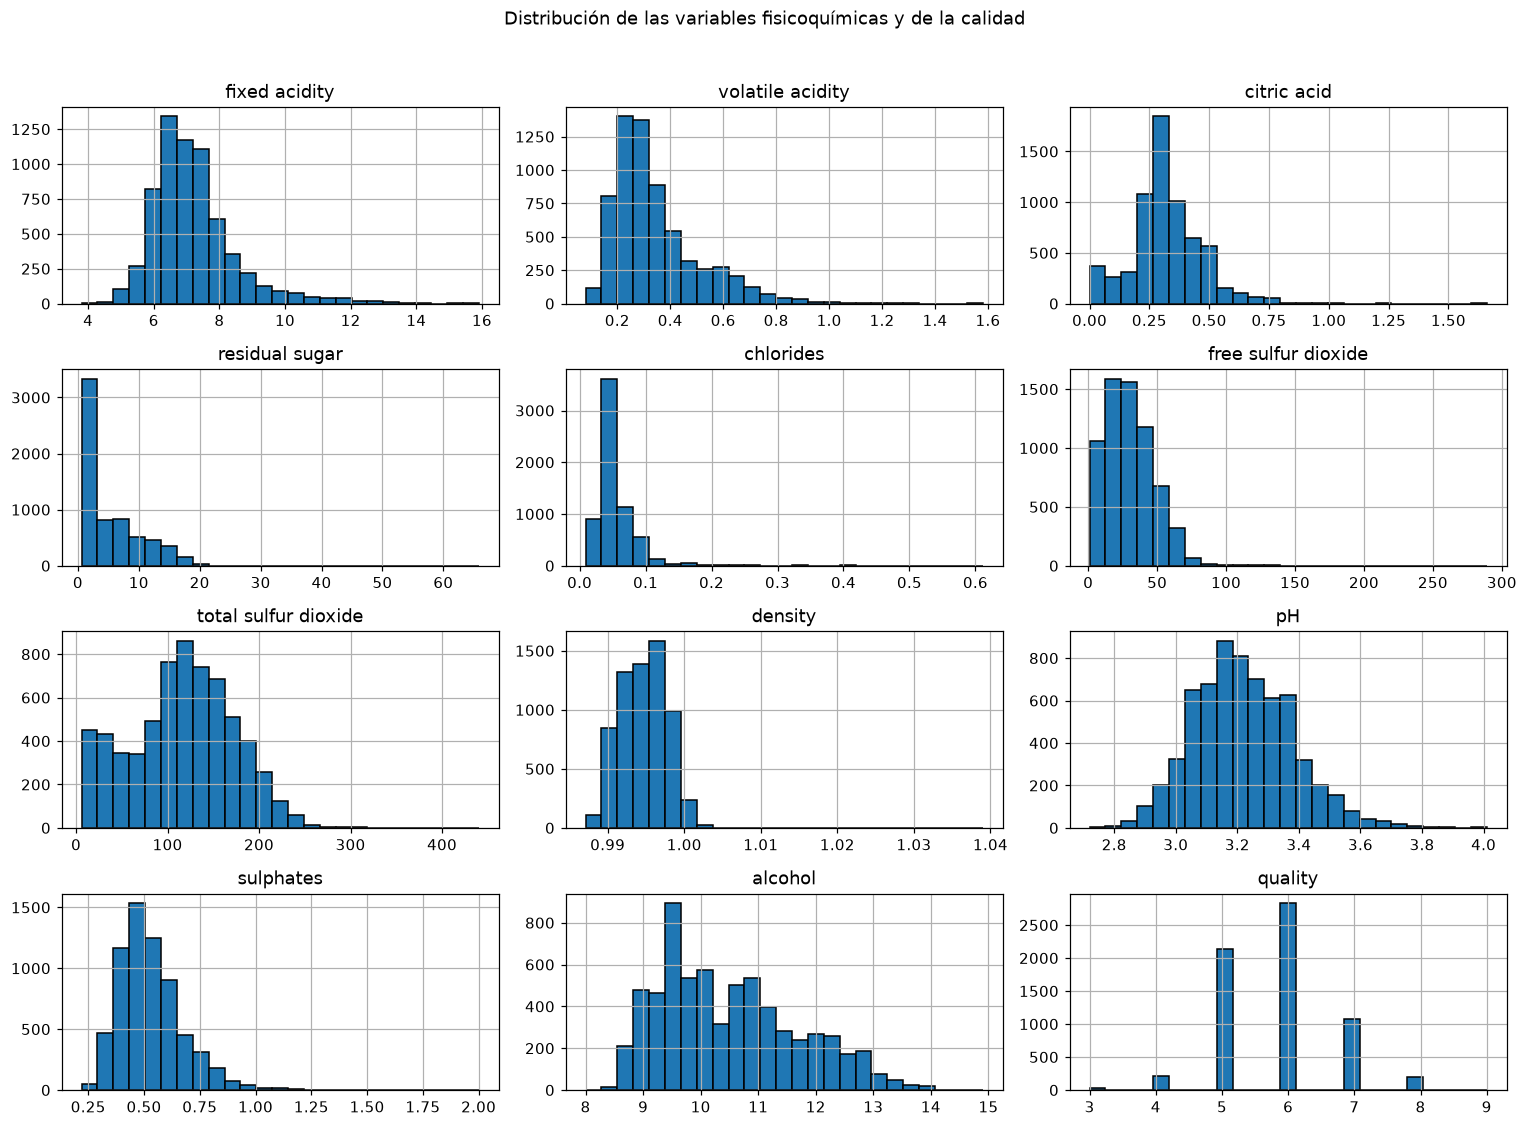

In [ ]:
# Graficamos histogramas para reconocer asimetrías, concentraciones y colas. Para este caso usamos 25 intervalos como un nivel de detalle visual para esta exploración.
columnas_numericas = [c for c in vinos.columns if c != "tipo"]
vinos[columnas_numericas].hist(figsize=(14, 10), bins=25, edgecolor="black")
plt.suptitle("Distribución de las variables fisicoquímicas y de la calidad", y=1.02)
plt.tight_layout()
plt.show()

En los histogramas se pueden observar con más detalle las distribuciones: el azúcar residual y los cloruros presentaron concentración en valores bajos y colas hacia valores altos. Esto explica por qué sus promedios no describen tan bien una muestra típica como sus medianas. 
En este caso quality se concentró entre 5 y 6, de modo que habrá menos ejemplos para aprender las calificaciones extremas.

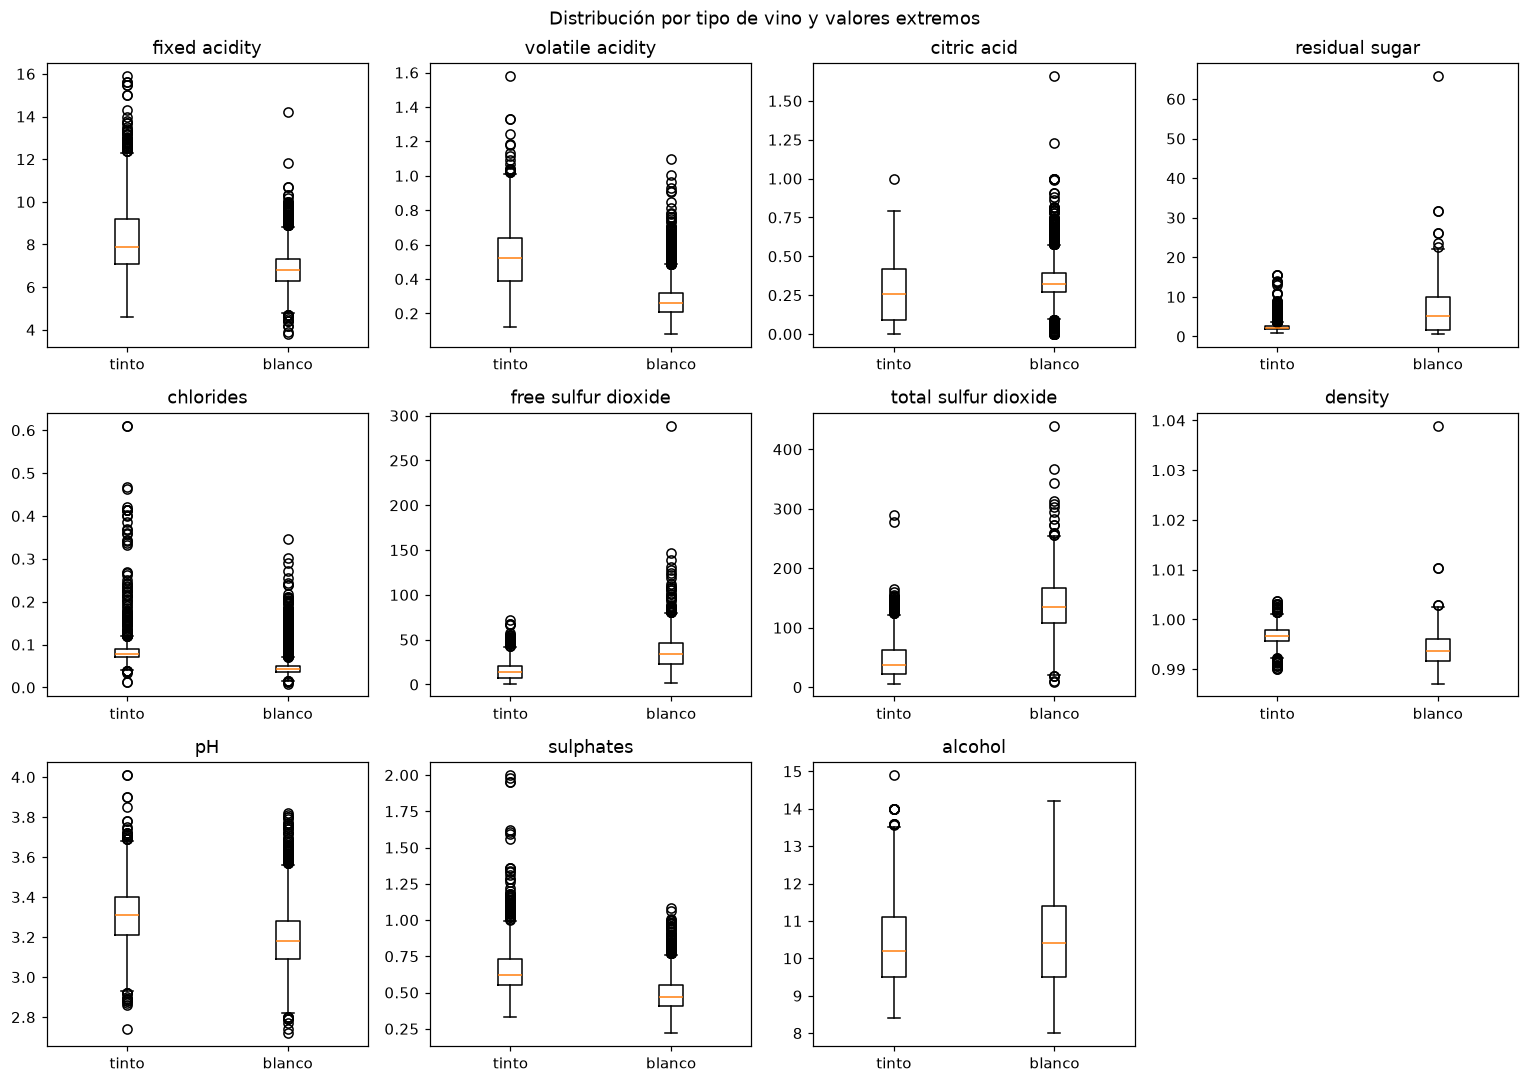

,tipo,variable,atípicos,%
0,blanco,fixed acidity,119,2.43
1,blanco,volatile acidity,186,3.80
2,blanco,citric acid,270,5.51
3,blanco,residual sugar,7,0.14
4,blanco,chlorides,208,4.25
5,blanco,free sulfur dioxide,50,1.02
6,blanco,total sulfur dioxide,19,0.39
7,blanco,density,5,0.10
8,blanco,pH,75,1.53
9,blanco,sulphates,124,2.53


In [ ]:
# Comparamos las mediciones por tipo con un eje por variable, porque sus unidades difieren.
mediciones = [col for col in vinos.columns if col not in ["quality", "tipo"]]
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for col, ax in zip(mediciones, axes.flat):
    ax.boxplot([tinto[col], blanco[col]], tick_labels=["tinto", "blanco"], showfliers=True)
    ax.set_title(col)
axes.flat[-1].set_visible(False)
fig.suptitle("Distribución por tipo de vino y valores extremos")
plt.tight_layout()
plt.show()
# Si los boxplots muestran extremos, con IQR contamos cuántos hubo por tipo.
resumen_outliers = []
for tipo, grupo in vinos.groupby("tipo"):
    for col in mediciones:
        q1, q3 = grupo[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        extremos = (grupo[col] < q1 - 1.5*iqr) | (grupo[col] > q3 + 1.5*iqr)
        resumen_outliers.append({"tipo": tipo, "variable": col,
            "atípicos": int(extremos.sum()), "%": round(100*extremos.mean(), 2)})
display(pd.DataFrame(resumen_outliers))

Al comparar los tipos de vino, observamos que la regla del IQR señaló 155 vinos tintos con azúcar residual atípico (9.69%), frente a 7 blancos (0.14%). Esto nos muestra que un mismo valor debe interpretarse respecto a la distribución de su tipo: ser atípico no significa necesariamente ser incorrecto. En cloruros también hubo más extremos relativos entre tintos (7.00%) que entre blancos (4.25%). En este caso decidí conservar estos registros porque la regla solo identifica valores poco habituales. Los conteos son por variable y no se pueden sumar como si fueran vinos distintos, ya que una fila puede aparecer en varias columnas.

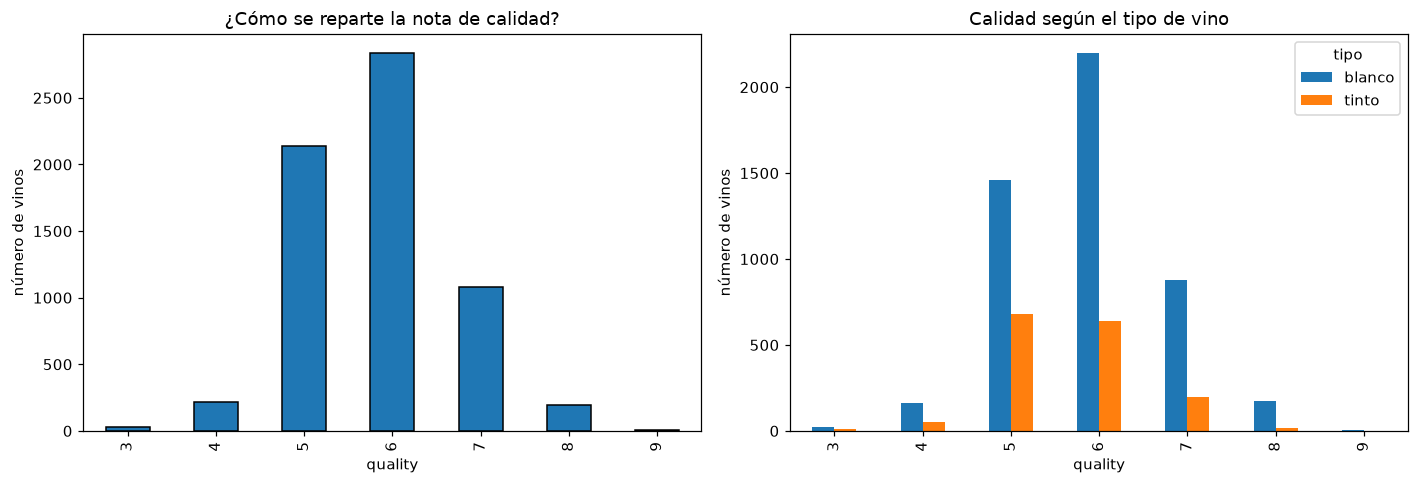

Proporción de vinos con quality >= 7: 0.1966


In [ ]:
# Comparamos la distribución de quality en total y por tipo de vino, para esto calculamos la proporción con quality >= 7 para revisar el desbalance del objetivo binario.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
vinos["quality"].value_counts().sort_index().plot(kind="bar", ax=axes[0], edgecolor="black")
axes[0].set_title("¿Cómo se reparte la calificación de calidad?")
axes[0].set_xlabel("quality")
axes[0].set_ylabel("número de vinos")

vinos.groupby(["quality", "tipo"]).size().unstack().plot(kind="bar", ax=axes[1])
axes[1].set_title("Calidad según el tipo de vino")
axes[1].set_xlabel("quality")
axes[1].set_ylabel("número de vinos")
plt.tight_layout()
plt.show()

print("Proporción de vinos con quality >= 7:",
      round(float((vinos['quality'] >= 7).mean()), 4))

En estas gráficas podemos observar que solo 19.66% de las muestras originales tuvo quality >= 7. aproximadamente cuatro de cada cinco pertenecieron a la otra clase. Un clasificador que siempre eligiera esa mayoría podría alcanzar cerca de 80% de accuracy sin detectar ningún vino de calidad alta. Por eso la evaluación debe incluir recall y precisión de la clase positiva, además del porcentaje global de aciertos. Esta proporción se volverá a revisar después de retirar duplicados.

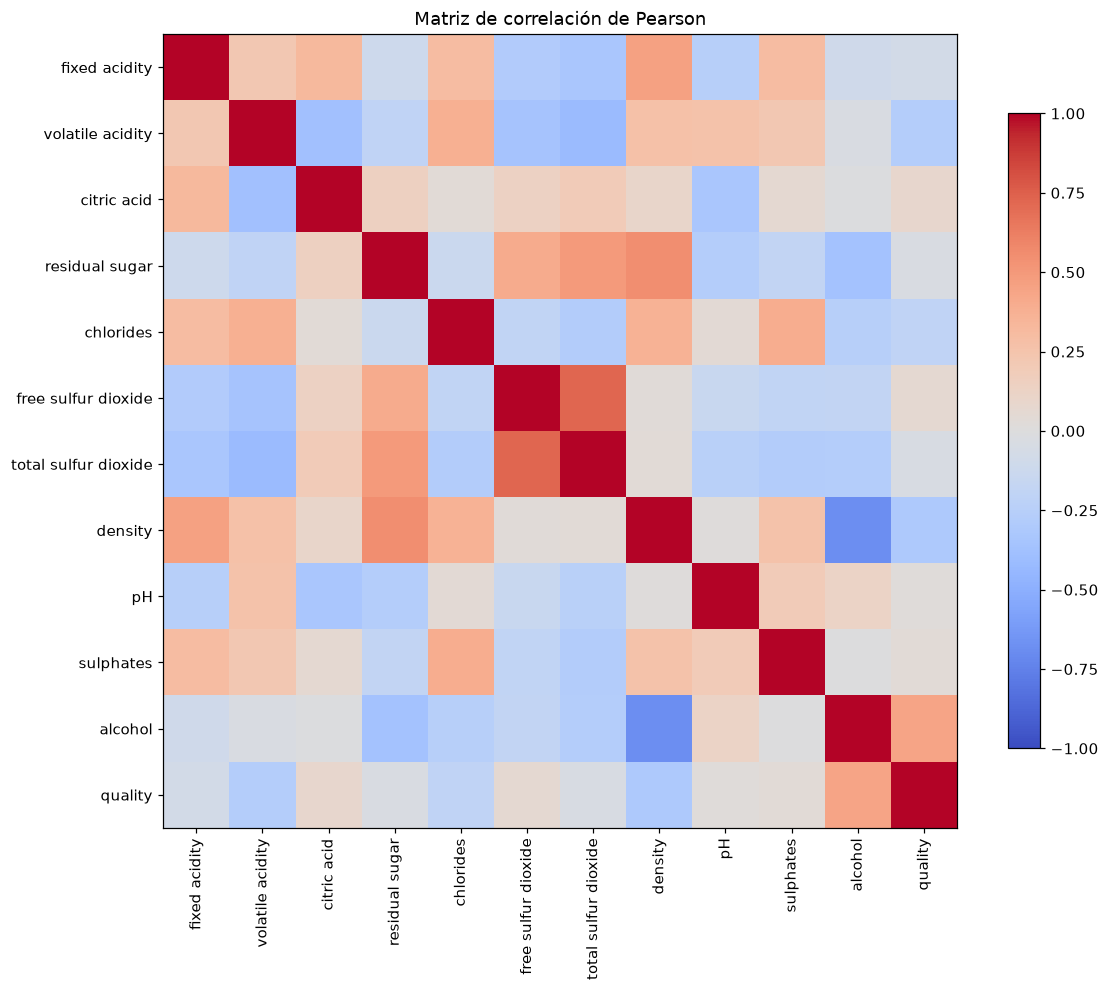

Correlación de cada variable con la calidad:
quality                 1.000
alcohol                 0.444
citric acid             0.086
free sulfur dioxide     0.055
sulphates               0.038
pH                      0.020
residual sugar         -0.037
total sulfur dioxide   -0.041
fixed acidity          -0.077
chlorides              -0.201
volatile acidity       -0.266
density                -0.306


In [ ]:
# Calculamos Pearson para explorar asociaciones lineales entre las variables numéricas, además comparamos su relación con quality sin interpretar correlación como causalidad.
correlaciones = vinos[columnas_numericas].corr()

fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlaciones.columns)))
ax.set_xticklabels(correlaciones.columns, rotation=90)
ax.set_yticks(range(len(correlaciones.columns)))
ax.set_yticklabels(correlaciones.columns)
fig.colorbar(imagen, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

print("Correlación de cada variable con la calidad:")
print(correlaciones["quality"].sort_values(ascending=False).round(3).to_string())

En la matriz podemos observar que el alcohol tuvo la asociación lineal positiva más alta con quality (0.444), mientras que densidad (−0.306) y acidez volátil (−0.266) mostraron relaciones negativas. Estas magnitudes nos proporcionan información útil aunque no sirven como una separación perfecta de la calidad. Las correlaciones cercanas a cero, como la de pH (0.020), tampoco bastan para descartar una variable: podría aportar relaciones no lineales o interactuar con otras mediciones.

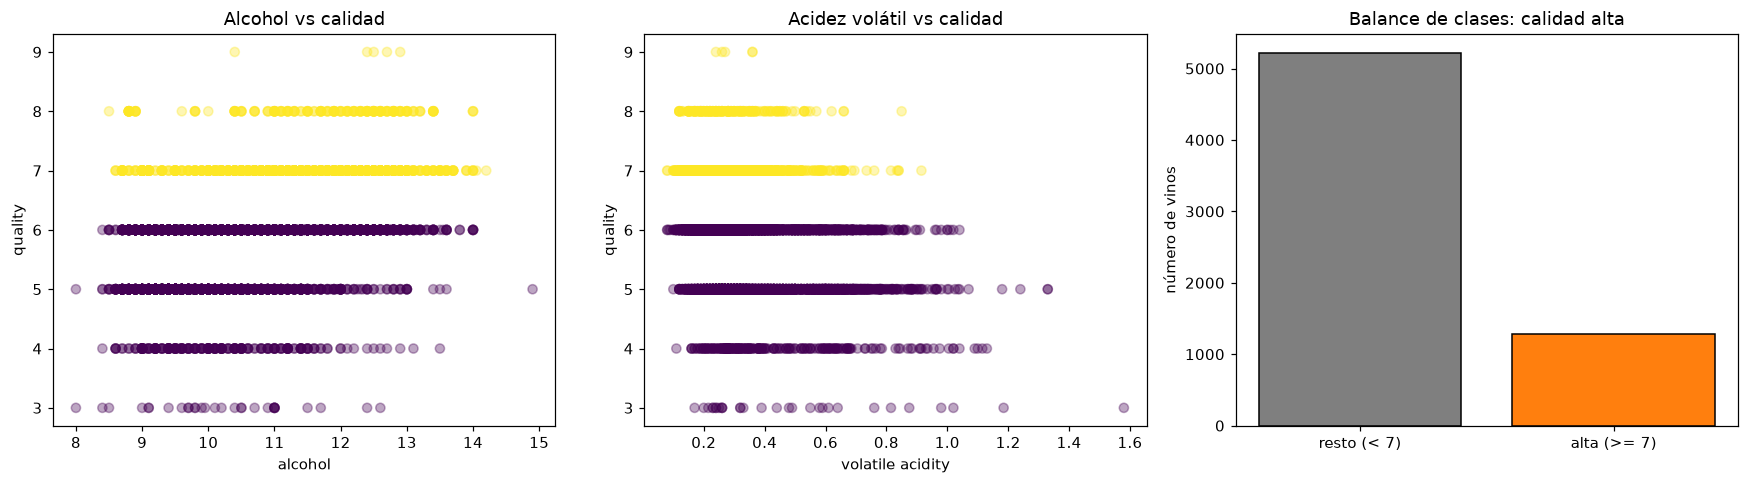

quality
0    0.803
1    0.197


In [ ]:
# Comparamos alcohol y acidez volátil con la calificación y coloreo por calidad alta. El conteo de clases nos permite ver si accuracy podría ocultar errores en la minoría.
alta = (vinos["quality"] >= 7).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(vinos["alcohol"], vinos["quality"], c=alta, cmap="viridis", alpha=0.35)
axes[0].set_xlabel("alcohol")
axes[0].set_ylabel("quality")
axes[0].set_title("Alcohol vs calidad")

axes[1].scatter(vinos["volatile acidity"], vinos["quality"], c=alta, cmap="viridis", alpha=0.35)
axes[1].set_xlabel("volatile acidity")
axes[1].set_ylabel("quality")
axes[1].set_title("Acidez volátil vs calidad")

conteo = alta.value_counts().sort_index()
axes[2].bar(["resto (< 7)", "alta (>= 7)"], [conteo.get(0, 0), conteo.get(1, 0)],
            color=["tab:gray", "tab:orange"], edgecolor="black")
axes[2].set_title("Balance de clases: calidad alta")
axes[2].set_ylabel("número de vinos")
plt.tight_layout()
plt.show()

print(alta.value_counts(normalize=True).round(3).to_string())

En las dispersiones podemos observar una superposición de calificaciones que indica que alcohol o acidez volátil, por separado, no ofrecen una regla clara para distinguir todos los vinos de calidad alta. El balance de 80.3% frente a 19.7% reforzó la necesidad de combinar variables y medir cuántos positivos detecta el modelo.
Con estas diferencias, decidí conservar tipo como predictor. El desbalance también fue una razón para revisar recall y precisión además de accuracy.

## Siguiente paso

Después de revisar los datos, elimino los duplicados y considero calidad alta a los vinos con calificación de 7 o más. En `train.py` uso el modelo Extra Trees elegido en la semana 3. En esta actividad comparo sus parámetros y guardo cada corrida en MLflow.
